# UrbanHub — Partie 2 : flux streaming, mobilité urbaine (vélos en libre-service)

Données : API CityBikes, état des stations de 10 grandes villes collecté toutes les 2 min 30.
Pré-requis : `python -m src.streaming_citybikes.collector` a tourné (idéalement plusieurs jours), puis `python -m src.streaming_citybikes.process`.

L'API ne fournit pas d'historique : la période d'analyse correspond à la période de collecte.

In [1]:
# ── Imports ──
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.streaming_citybikes import config

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)
FIG_DIR = ROOT / "reports" / "figures" / "partie2"
FIG_DIR.mkdir(parents=True, exist_ok=True)
STEP_MIN = config.INTERVAL_S / 60

In [2]:
# ── Chargement ──
df = pd.read_parquet(config.PROCESSED_DIR)
df["sid"] = df["network"] + ":" + df["station_id"]           # identifiant unique tous réseaux
df["local"] = df["collected_at"].dt.tz_convert("Europe/Paris")
df["hour"] = df["local"].dt.hour
df["weekend"] = df["local"].dt.dayofweek >= 5

# capacité de référence : médiane observée (robuste aux bornes temporairement en panne)
df["cap_ref"] = df.groupby("sid")["capacity"].transform("median")
df = df[df["cap_ref"] > 0].copy()
df["occupancy"] = (df["bikes_available"] / df["cap_ref"]).clip(0, 1)
df["empty"] = df["bikes_available"] == 0
df["full"] = df["free_slots"] == 0

# contrôle qualité : un réseau qui ne déclare aucun vélo sur toute la période a un flux inexploitable
# (cas de LeVélo Marseille : 0 vélo sur toutes les stations, à chaque collecte)
velos_ville = df.groupby("city")["bikes_available"].sum()
sans_velos = velos_ville[velos_ville == 0].index.tolist()
if sans_velos:
    print("réseaux exclus (aucun vélo déclaré, flux inexploitable) :", sans_velos)
    df = df[~df["city"].isin(sans_velos)].copy()

couverture = df.groupby("city").agg(stations=("sid", "nunique"), snapshots=("collected_at", "nunique"),
                                    debut=("local", "min"), fin=("local", "max"))
couverture["heures"] = ((couverture["fin"] - couverture["debut"]).dt.total_seconds() / 3600).round(1)
print(f"{len(df):,} relevés, {df['sid'].nunique():,} stations")
if couverture["heures"].max() < 24:
    print("ATTENTION : moins de 24h de collecte, les profils journaliers ne sont pas fiables")
couverture.sort_values("stations", ascending=False)

réseaux exclus (aucun vélo déclaré, flux inexploitable) : ['Marseille']
9,196 relevés, 3,066 stations
ATTENTION : moins de 24h de collecte, les profils journaliers ne sont pas fiables


,stations,snapshots,debut,fin,heures
city,,,,,
Paris,1496,3,2026-11-18 16:07:46+01:00,2026-11-18 16:10:25+01:00,0.0
Lyon,456,3,2026-11-18 16:07:46+01:00,2026-11-18 16:10:25+01:00,0.0
Toulouse,454,3,2026-11-18 16:07:46+01:00,2026-11-18 16:10:25+01:00,0.0
Lille,262,3,2026-11-18 16:07:46+01:00,2026-11-18 16:10:25+01:00,0.0
Bordeaux,217,3,2026-11-18 16:07:46+01:00,2026-11-18 16:10:25+01:00,0.0
Rennes,57,3,2026-11-18 16:07:46+01:00,2026-11-18 16:10:25+01:00,0.0
Montpellier,48,3,2026-11-18 16:07:46+01:00,2026-11-18 16:10:25+01:00,0.0
Strasbourg,40,3,2026-11-18 16:07:46+01:00,2026-11-18 16:10:25+01:00,0.0
Nantes,36,3,2026-11-18 16:07:46+01:00,2026-11-18 16:10:25+01:00,0.0


In [3]:
# ── Référentiel des stations ──
def distance_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

st = (df.groupby("sid").agg(city=("city", "first"), name=("station_name", "first"),
                            lat=("latitude", "median"), lon=("longitude", "median"),
                            capacite=("cap_ref", "first"))
        .reset_index())
centers = st["city"].map(config.CITY_CENTERS)
st["dist_centre_km"] = distance_km(st["lat"], st["lon"], centers.str[0], centers.str[1])

def carte(data, col, titre, ax, cmap="RdYlGn", vmin=0, vmax=1):
    sc = ax.scatter(data["lon"].to_numpy(), data["lat"].to_numpy(), c=data[col].to_numpy(),
                    cmap=cmap, vmin=vmin, vmax=vmax, s=12, alpha=0.85)
    ax.set_title(titre); ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect(1.4)
    return sc

## Q1 — Quelles stations présentent le plus fort taux d'utilisation ?

Indicateur : **rotations par jour** = nombre de vélos pris ou déposés par jour, divisé par la capacité de la station. Le nombre de mouvements est estimé par la somme des variations absolues du nombre de vélos entre deux collectes. C'est un minimum : un vélo pris puis rendu dans les mêmes 2 min 30 ne se voit pas. Les variations qui suivent un trou de collecte de plus de 10 minutes sont ignorées.

In [4]:
# ── Mouvements entre deux collectes ──
df = df.sort_values(["sid", "collected_at"])
g = df.groupby("sid")
df["mouvements"] = g["bikes_available"].diff().abs()
gap = g["collected_at"].diff().dt.total_seconds() / 60
df.loc[gap > 10, "mouvements"] = np.nan

usage = df.groupby("sid").agg(mouvements=("mouvements", "sum"), n=("mouvements", "count"))
usage["jours_observes"] = usage["n"] * STEP_MIN / 1440
st = st.merge(usage, on="sid")
st["mouvements_jour"] = st["mouvements"] / st["jours_observes"]
st["rotations_jour"] = st["mouvements_jour"] / st["capacite"]

top = st.sort_values("rotations_jour", ascending=False).head(15)
top[["city", "name", "capacite", "mouvements_jour", "rotations_jour"]].round(1)

,city,name,capacite,mouvements_jour,rotations_jour
1850,Toulouse,00290 - AMIDONNIERS - DEBAT-PONSAN,13.0,1152.0,88.6
2160,Toulouse,00032 - MUSEE SAINT-RAYMOND,10.0,864.0,86.4
1875,Toulouse,PATTE D'OIE - MÉTRO,14.0,1152.0,82.3
1859,Toulouse,PARGAMINIÈRES - LAKANAL,7.0,576.0,82.3
1979,Toulouse,AV. DE MURET TRAMWAY,18.0,1440.0,80.0
2186,Toulouse,BILLIÈRES - CHAMPÊTRE,18.0,1440.0,80.0
2098,Toulouse,BORDEBLANCHE - BROUSSIN,12.0,864.0,72.0
2051,Toulouse,RTE DE LAUNAGUET - DELBO,12.0,864.0,72.0
2268,Toulouse,ST-MARTIN-DU-TOUCH GARE,13.0,864.0,66.5
2987,Lille,Place Philippe Lebon,18.0,1152.0,64.0


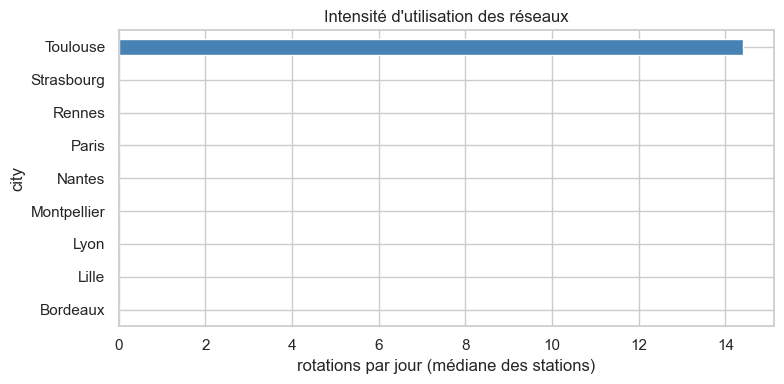

In [5]:
# ── Utilisation par ville ──
par_ville = st.groupby("city")["rotations_jour"].median().sort_values()
ax = par_ville.plot.barh(color="steelblue", figsize=(8, 4))
ax.set_xlabel("rotations par jour (médiane des stations)")
ax.set_title("Intensité d'utilisation des réseaux")
plt.tight_layout(); plt.savefig(FIG_DIR / "q1_utilisation_villes.png", dpi=120); plt.show()

## Q2 — Peut-on identifier des zones où l'offre de vélos est insuffisante ?

On découpe chaque ville en carreaux d'environ 1 km × 1 km. Pour chaque zone, on mesure la part du temps où ses stations sont **vides** (0 vélo) et le nombre moyen de vélos disponibles par station. Une zone est jugée en offre insuffisante si ses stations sont vides plus de 25 % du temps.

In [6]:
# ── Indicateurs par station puis par zone ──
etat = df.groupby("sid").agg(part_vide=("empty", "mean"), part_pleine=("full", "mean"),
                             velos_moyens=("bikes_available", "mean"))
st = st.merge(etat, on="sid")
st["zone"] = (st["city"] + "_" + (st["lat"] / 0.009).round().astype(int).astype(str) + "_"
              + (st["lon"] / 0.013).round().astype(int).astype(str))

zones = (st.groupby("zone").agg(city=("city", "first"), lat=("lat", "mean"), lon=("lon", "mean"),
                                stations=("sid", "size"), part_vide=("part_vide", "mean"),
                                velos_par_station=("velos_moyens", "mean"),
                                dist_centre_km=("dist_centre_km", "mean"))
          .reset_index())
insuff = zones[(zones["part_vide"] > 0.25) & (zones["stations"] >= 2)]
print(f"{len(insuff)} zones en offre insuffisante sur {len(zones)}")
print(insuff.groupby("city").size().rename("zones insuffisantes").to_string())
insuff.sort_values("part_vide", ascending=False).head(15).round(2)

61 zones en offre insuffisante sur 859
city
Bordeaux        4
Lille           4
Lyon           21
Montpellier     4
Paris          20
Strasbourg      1
Toulouse        7


,zone,city,lat,lon,stations,part_vide,velos_par_station,dist_centre_km
725,Strasbourg_5399_597,Strasbourg,48.59,7.76,2,1.00,0.00,1.96
570,Paris_5431_187,Paris,48.88,2.43,2,1.00,0.00,6.29
274,Lyon_5088_369,Lyon,45.79,4.80,2,1.00,0.00,4.40
264,Lyon_5087_369,Lyon,45.79,4.80,2,1.00,0.00,3.89
226,Lyon_5084_368,Lyon,45.76,4.79,2,1.00,0.00,3.99
546,Paris_5430_185,Paris,48.87,2.40,9,0.78,0.22,4.14
227,Lyon_5084_369,Lyon,45.76,4.80,4,0.75,0.50,3.07
294,Montpellier_4845_298,Montpellier,43.61,3.87,7,0.71,0.71,0.71
254,Lyon_5086_371,Lyon,45.77,4.82,9,0.67,1.00,1.44
158,Lille_5631_244,Lille,50.68,3.17,2,0.67,0.33,9.73


C:\Users\Steven\AppData\Local\Temp\ipykernel_12352\1819759620.py:6: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  fig.colorbar(sc, ax=axes, shrink=0.7, label="part du temps vide")


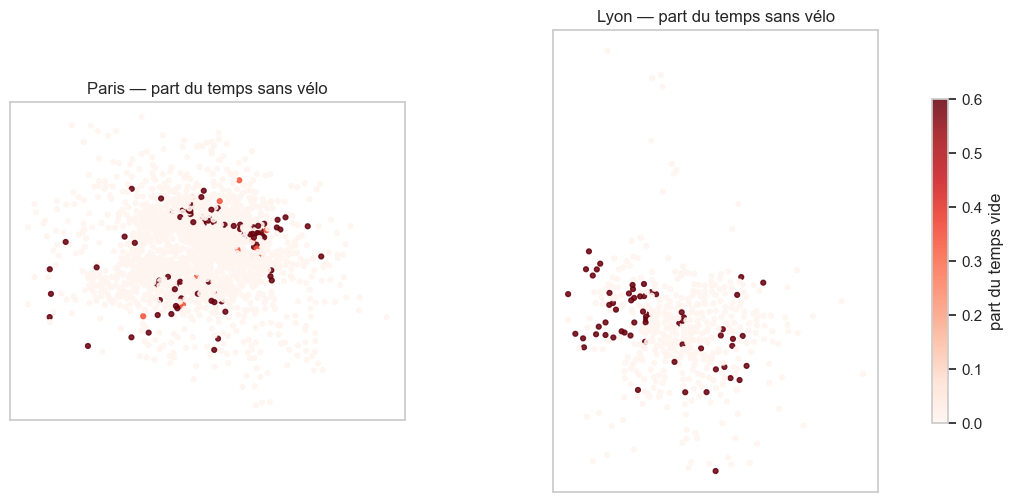

In [7]:
# ── Carte des stations vides (2 plus grands réseaux) ──
villes = st["city"].value_counts().index[:2]
fig, axes = plt.subplots(1, len(villes), figsize=(14, 6))
for ax, v in zip(np.atleast_1d(axes), villes):
    sc = carte(st[st["city"] == v], "part_vide", f"{v} — part du temps sans vélo", ax, cmap="Reds", vmax=0.6)
fig.colorbar(sc, ax=axes, shrink=0.7, label="part du temps vide")
plt.savefig(FIG_DIR / "q2_stations_vides.png", dpi=120, bbox_inches="tight"); plt.show()

## Q3 — Quels sont les pics d'utilisation journaliers ?

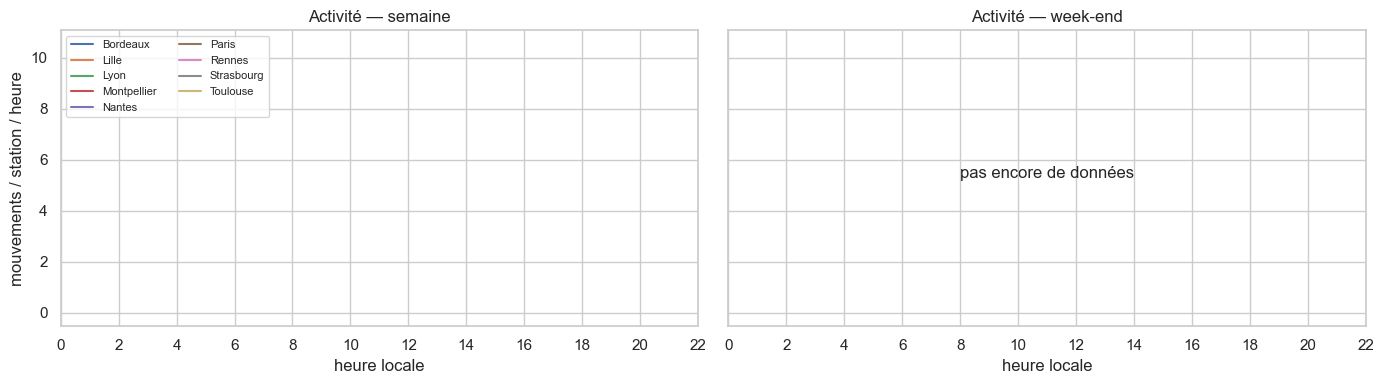

2 heures les plus actives en semaine, par ville :


,city,hour,mvt_heure
0,Bordeaux,16,1.94
1,Lille,16,1.28
2,Lyon,16,0.00
3,Montpellier,16,0.25
4,Nantes,16,2.00
5,Paris,16,4.68
6,Rennes,16,2.11
7,Strasbourg,16,0.30
8,Toulouse,16,10.55


In [8]:
# ── Activité moyenne par heure (mouvements par station et par heure) ──
act = (df.groupby(["city", "weekend", "hour"])
         .agg(mvt=("mouvements", "mean"))   # mouvements moyens par station et par collecte
         .reset_index())
act["mvt_heure"] = act["mvt"] * 60 / STEP_MIN

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (we, titre) in zip(axes, [(False, "semaine"), (True, "week-end")]):
    sub = act[act["weekend"] == we]
    for v, s in sub.groupby("city"):
        ax.plot(s["hour"].to_numpy(), s["mvt_heure"].to_numpy(), label=v, lw=1.5)
    ax.set(title=f"Activité — {titre}", xlabel="heure locale", xticks=range(0, 24, 2))
    if sub.empty:
        ax.text(0.5, 0.5, "pas encore de données", ha="center", transform=ax.transAxes)
    else:
        ax.legend(fontsize=8, ncol=2)
axes[0].set_ylabel("mouvements / station / heure")
plt.tight_layout(); plt.savefig(FIG_DIR / "q3_pics_journaliers.png", dpi=120); plt.show()

pics = act[~act["weekend"]].sort_values("mvt_heure", ascending=False).groupby("city").head(2)
print("2 heures les plus actives en semaine, par ville :")
pics.sort_values(["city", "hour"])[["city", "hour", "mvt_heure"]].round(2)

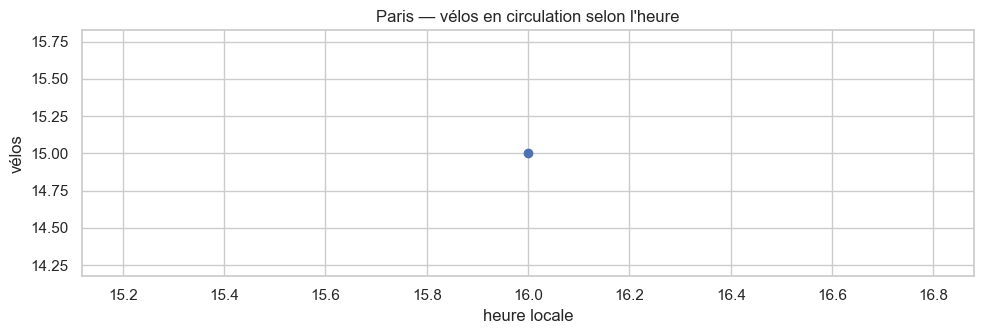

In [9]:
# ── Vélos en circulation : vélos absents des stations par rapport au maximum observé ──
tot = df.groupby(["city", "collected_at"])["bikes_available"].sum().reset_index()
tot["en_circulation"] = tot.groupby("city")["bikes_available"].transform("max") - tot["bikes_available"]
tot["hour"] = tot["collected_at"].dt.tz_convert("Europe/Paris").dt.hour
v = st["city"].value_counts().index[0]
prof = tot[tot["city"] == v].groupby("hour")["en_circulation"].mean()
ax = prof.plot(marker="o", figsize=(10, 3.5))
ax.set(title=f"{v} — vélos en circulation selon l'heure", xlabel="heure locale", ylabel="vélos")
plt.tight_layout(); plt.savefig(FIG_DIR / "q3_velos_circulation.png", dpi=120); plt.show()

## Q4 — Existe-t-il des déséquilibres géographiques dans la disponibilité des vélos ?

On compare le taux de remplissage des stations (vélos / capacité) selon la distance au centre-ville et le moment de la journée. Si les vélos « descendent » vers le centre le matin et remontent le soir, on parle de **mouvement pendulaire**.

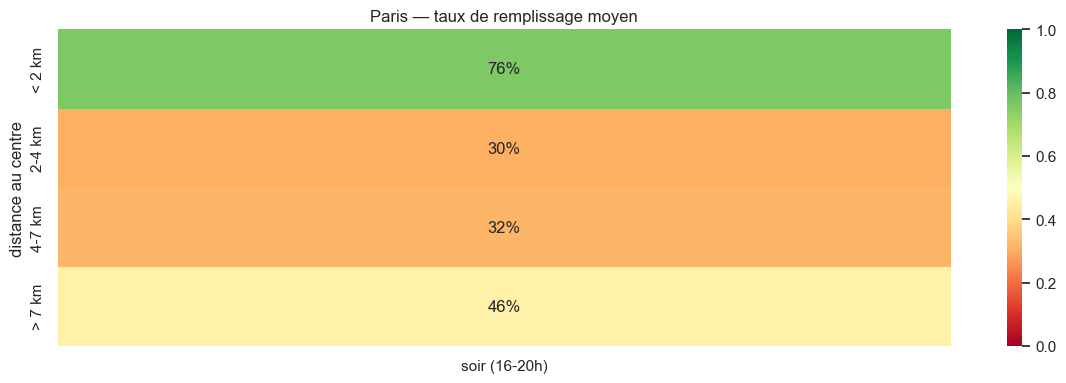

In [10]:
# ── Remplissage selon la distance au centre et le créneau horaire ──
creneaux = {**{h: "nuit (0-6h)" for h in range(0, 6)}, **{h: "matin (6-10h)" for h in range(6, 10)},
            **{h: "journée (10-16h)" for h in range(10, 16)}, **{h: "soir (16-20h)" for h in range(16, 20)},
            **{h: "soirée (20-24h)" for h in range(20, 24)}}
ordre = ["nuit (0-6h)", "matin (6-10h)", "journée (10-16h)", "soir (16-20h)", "soirée (20-24h)"]
d = df.merge(st[["sid", "dist_centre_km"]], on="sid")
d["creneau"] = d["hour"].map(creneaux)
d["anneau"] = pd.cut(d["dist_centre_km"], [0, 2, 4, 7, 100], labels=["< 2 km", "2-4 km", "4-7 km", "> 7 km"])

v = st["city"].value_counts().index[0]
pv = d[d["city"] == v].pivot_table(index="anneau", columns="creneau", values="occupancy",
                                   aggfunc="mean", observed=True)
pv = pv[[c for c in ordre if c in pv.columns]]   # créneaux pas encore collectés : ignorés
sns.heatmap(pv, annot=True, fmt=".0%", cmap="RdYlGn", vmin=0, vmax=1)
plt.title(f"{v} — taux de remplissage moyen"); plt.ylabel("distance au centre"); plt.xlabel("")
plt.tight_layout(); plt.savefig(FIG_DIR / "q4_remplissage_distance.png", dpi=120); plt.show()

C:\Users\Steven\AppData\Local\Temp\ipykernel_12352\1198081971.py:14: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  fig.colorbar(sc, ax=axes, shrink=0.7, label="vélos / capacité")


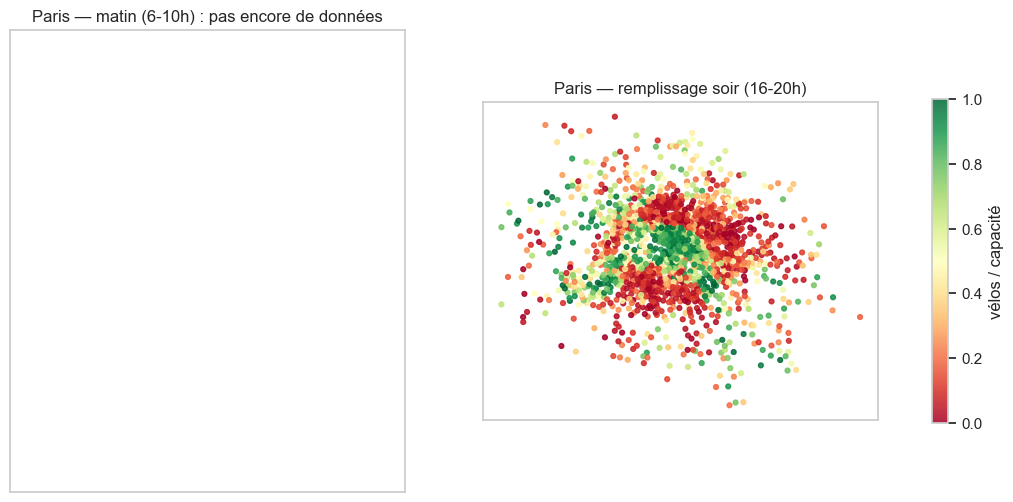

In [11]:
# ── Carte matin vs soir ──
occ = d[d["creneau"].isin(["matin (6-10h)", "soir (16-20h)"])].pivot_table(
    index="sid", columns="creneau", values="occupancy", aggfunc="mean")
m = st.merge(occ, on="sid")
m = m[m["city"] == v]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sc = None
for ax, c in zip(axes, ["matin (6-10h)", "soir (16-20h)"]):
    if c in m.columns:
        sc = carte(m, c, f"{v} — remplissage {c}", ax)
    else:
        ax.set_title(f"{v} — {c} : pas encore de données"); ax.set_xticks([]); ax.set_yticks([])
if sc is not None:
    fig.colorbar(sc, ax=axes, shrink=0.7, label="vélos / capacité")
plt.savefig(FIG_DIR / "q4_carte_matin_soir.png", dpi=120, bbox_inches="tight"); plt.show()

In [12]:
# ── Indice de déséquilibre par ville : dispersion du remplissage entre stations ──
deseq = (d.groupby(["city", "collected_at"])["occupancy"].std()
          .groupby("city").mean().sort_values(ascending=False))
print("écart-type moyen du remplissage entre stations (plus c'est haut, plus c'est déséquilibré) :")
deseq.round(3).to_frame("indice_desequilibre")

écart-type moyen du remplissage entre stations (plus c'est haut, plus c'est déséquilibré) :


,indice_desequilibre
city,
Paris,0.331
Toulouse,0.285
Lyon,0.285
Bordeaux,0.251
Rennes,0.210
Strasbourg,0.203
Lille,0.193
Nantes,0.183
Montpellier,0.158


## Q5 — Peut-on détecter des stations critiques nécessitant un rééquilibrage ?

Une station est **critique** si, aux heures de pointe (7-10h et 17-20h en semaine), elle est vide ou pleine plus de 30 % du temps :
- vide : les usagers ne trouvent pas de vélo, il faut **réapprovisionner** ;
- pleine : les usagers ne peuvent pas rendre leur vélo, il faut **délester**.

In [13]:
# ── Détection des stations critiques ──
pointe = df[(~df["weekend"]) & df["hour"].isin([7, 8, 9, 17, 18, 19])]
if pointe.empty:   # pas encore de jour de semaine collecté : on prend toutes les heures de pointe
    pointe = df[df["hour"].isin([7, 8, 9, 17, 18, 19])]
if pointe.empty:   # pas encore d'heure de pointe collectée : on prend toutes les données
    print("pas encore de données aux heures de pointe : calcul sur toute la période")
    pointe = df
crit = pointe.groupby("sid").agg(vide_pointe=("empty", "mean"), pleine_pointe=("full", "mean"))
crit = st[["sid", "city", "name", "capacite", "lat", "lon"]].merge(crit, on="sid")
crit["action"] = np.select(
    [crit["vide_pointe"] > 0.3, crit["pleine_pointe"] > 0.3],
    ["réapprovisionner", "délester"], default="")
crit["urgence"] = crit[["vide_pointe", "pleine_pointe"]].max(axis=1)
critiques = crit[crit["action"] != ""].sort_values("urgence", ascending=False)

print(f"{len(critiques)} stations critiques sur {len(crit)}")
print(critiques.groupby(["city", "action"]).size().unstack(fill_value=0).to_string())
critiques.head(20)[["city", "name", "capacite", "vide_pointe", "pleine_pointe", "action"]].round(2)

pas encore de données aux heures de pointe : calcul sur toute la période
326 stations critiques sur 3066
action       délester  réapprovisionner
city                                   
Bordeaux            1                15
Lille               1                 8
Lyon                9                62
Montpellier         0                12
Paris              52                94
Rennes              0                 5
Strasbourg          0                 3
Toulouse           19                45


,city,name,capacite,vide_pointe,pleine_pointe,action
38,Rennes,Cucillé - Frac,25.0,1.0,0.0,réapprovisionner
2123,Toulouse,RENAN - VITRY,18.0,1.0,0.0,réapprovisionner
2283,Toulouse,PLACE DE LA DAURADE,23.0,0.0,1.0,délester
2269,Toulouse,SEPT DENIERS - TROÈNES,13.0,0.0,1.0,délester
2266,Toulouse,MONT LOUIS –AV. DE TOULOUSE,16.0,0.0,1.0,délester
2236,Toulouse,00085 - BARCELONE - LECLERC,22.0,0.0,1.0,délester
2233,Toulouse,CITÉ DE L'ESPACE,13.0,0.0,1.0,délester
2172,Toulouse,FER À CHEVAL - COURS DILLON,21.0,1.0,0.0,réapprovisionner
2121,Toulouse,POIDS DE L'HUILE,17.0,0.0,1.0,délester
2302,Montpellier,Jean de Beins,15.0,1.0,0.0,réapprovisionner


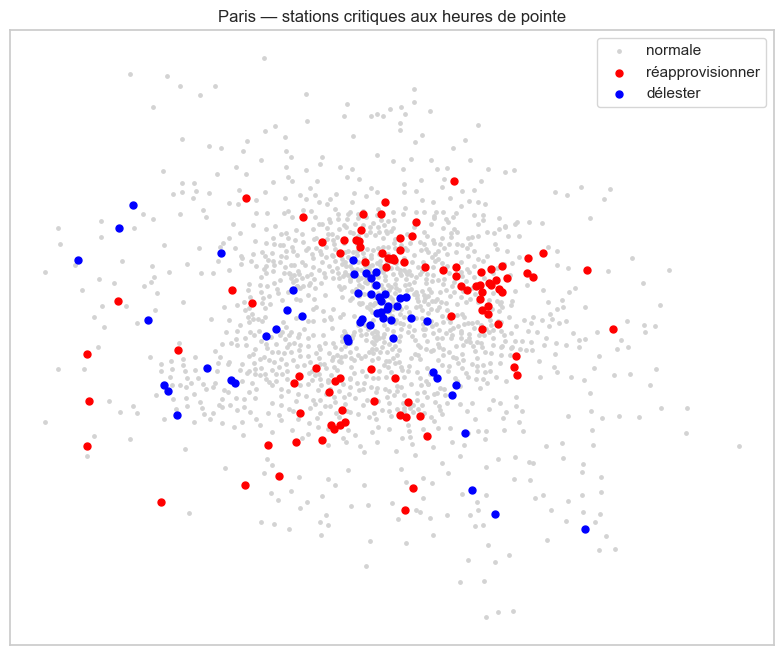

In [14]:
# ── Carte des stations critiques ──
v = st["city"].value_counts().index[0]
c = crit[crit["city"] == v]
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(c["lon"].to_numpy(), c["lat"].to_numpy(), s=6, color="lightgrey", label="normale")
for action, col in [("réapprovisionner", "red"), ("délester", "blue")]:
    s = c[c["action"] == action]
    ax.scatter(s["lon"].to_numpy(), s["lat"].to_numpy(), s=25, color=col, label=action)
ax.set_title(f"{v} — stations critiques aux heures de pointe"); ax.set_xticks([]); ax.set_yticks([])
ax.set_aspect(1.4); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "q5_stations_critiques.png", dpi=120); plt.show()

In [15]:
# ── Exports pour la partie 4 (analyse croisée) ──
df["heure_utc"] = df["collected_at"].dt.floor("h")
horaire = (df.groupby(["city", "heure_utc"])
             .agg(velos_disponibles=("bikes_available", "sum"), remplissage_moyen=("occupancy", "mean"),
                  mouvements=("mouvements", "sum"), stations=("sid", "nunique"))
             .reset_index())
out = config.PROCESSED_DIR.parent / "citybikes_hourly.parquet"
horaire.to_parquet(out, index=False)
critiques.to_csv(ROOT / "reports" / "partie2_stations_critiques.csv", index=False)
st.to_csv(ROOT / "reports" / "partie2_indicateurs_stations.csv", index=False)
print("exporté :", out)

exporté : S:\IPSSI\MIA 2e année\DATALAKE\Projet final\urbanhub\data\processed\citybikes_hourly.parquet


## Interprétation

À rédiger une fois que le collecteur a tourné plusieurs jours (dont au moins un jour de semaine et un week-end).